In [61]:
import pandas as pd
import jax.numpy as jnp
import matplotlib.pyplot as plt
import jax
import laser
from jax import jit
import plasticbundle as pbndl
import numpy as np
# import os
import matplotlib.animation as animation
from quadax import quadgk
from laser import jax_hermite
from matplotlib import colormaps as cm
import numpy as np
from scipy.signal import periodogram, welch
# os.environ["XLA_PYTHON_CLIENT_ALLOCATOR"] = "cuda_async"
import sys
sys.path.append("../acoustooptic_lab")
sys.path.append("../data")
from analysis import System as syst
def find_nearest(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return array[idx]
def find_idx(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return idx


def I_x(x, mode, waist, w, P_total, mux=0.0):
    n = mode[0]
    norm_n = 1.0 / jnp.sqrt((2.0**n) * jax.scipy.special.factorial(n))
    
    norm_factor = (2.0 / (jnp.pi * w**2))**0.25
    field_x = norm_factor * norm_n * jax_hermite(n, jnp.sqrt(2) * (x - mux) / w) * jnp.exp(-(x - mux)**2 / w**2)
    
    return jnp.sqrt(P_total) * (field_x**2)

def I_y(y, mode, waist, w, P_total, muy=0.0):
    m = mode[1]
    norm_m = 1.0 / jnp.sqrt((2.0 ** m) * jax.scipy.special.factorial(m))
    
    norm_factor = (2.0 / (jnp.pi * w ** 2)) ** 0.25
    field_y = norm_factor * norm_m * jax_hermite(m, jnp.sqrt(2) * (y - muy) / w) * jnp.exp(-(y - muy)**2 / w**2)
    
    return jnp.sqrt(P_total) * (field_y ** 2)

def x_integ(bounds, mode, waist, w, P_total, mux = 0.0):
    integ, info = quadgk(I_x, bounds, args=(mode, waist, w, P_total, mux))
    return integ

def y_integ(bounds, mode, waist, w, P_total, muy = 0.0):
    integ, info = quadgk(I_y, bounds, args=(mode, waist, w, P_total, muy))
    return integ
    
def lsum(mu, r, gap, mode, waist, w, targ_power, mux):
        return x_integ(jnp.array([-r, r]), mode, waist, w, targ_power, mux = mux) * y_integ(jnp.array([gap / 2, r]), mode, waist, w, targ_power, muy = mu) + x_integ(jnp.array([-r, r]), mode, waist, w, targ_power, mux = mux) * y_integ(jnp.array([-r, -gap / 2]), mode, waist, w, targ_power, muy = mu)

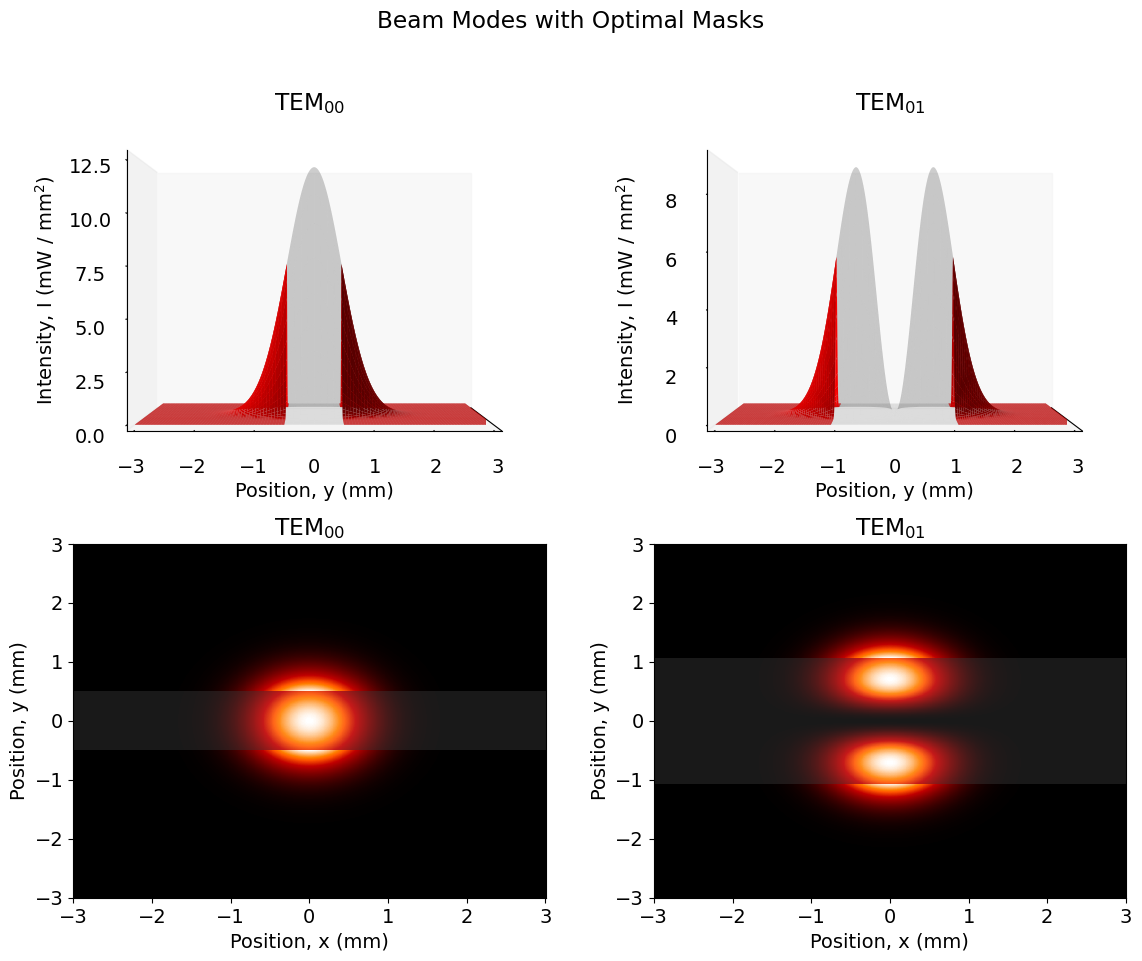

In [62]:
mode00 = jnp.array([0, 0], dtype=jnp.int32)
waist = 1
z = 0
w = waist * jnp.sqrt(1 + jnp.power(z / (jnp.pi * waist * 2 * 1 / 1064e-9), 2))
targ_power = 20

r = 3 * w
gap00 = waist
mux = 0
muy = 0

plt.rcParams.update({'font.size': 14})
fig = plt.figure(figsize = (12, 10))
ax1 = fig.add_subplot(2, 2, 1, projection='3d')
ax1.view_init(elev = 0, azim = 0, roll = 0)

x = jnp.linspace(-r, r, 1000)
y = jnp.linspace(-r, r, 1000)
y001 = jnp.linspace(-r, -gap00 / 2, 1000)
y002 = jnp.linspace(gap00 / 2, r, 1000)

ax1.plot_surface(x[jnp.newaxis, :], y[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode00, waist, w, targ_power, mux) * I_y(y[:, jnp.newaxis], mode00, waist, w, targ_power, muy), color = "k", alpha = 0.1)

ax1.plot_surface(x[jnp.newaxis, :], y001[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode00, waist, w, targ_power, mux) * I_y(y001[:, jnp.newaxis], mode00, waist, w, targ_power, muy), color = "r")
ax1.plot_surface(x[jnp.newaxis, :], y002[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode00, waist, w, targ_power, mux) * I_y(y002[:, jnp.newaxis], mode00, waist, w, targ_power, muy), color = "r")
ax1.grid(visible = False)
ax1.set_xticks(ticks = [])
ax1.set_title(r"TEM$_{\text{00}}$")
ax1.set_zlabel(r"Intensity, I ($\text{mW } / \text{ mm}^2$)")
ax1.set_ylabel("Position, y (mm)")
ax1.margins(0)
ax1.set_box_aspect(None, zoom = 1.5)


mode01 = jnp.array([0, 1], dtype=jnp.int32)
gap01 = waist * 2.134
y011 = jnp.linspace(-r, -gap01 / 2, 1000)
y012 = jnp.linspace(gap01 / 2, r, 1000)

ax2 = fig.add_subplot(2, 2, 2, projection='3d')
ax2.view_init(elev = 0, azim = 0, roll = 0)


ax2.plot_surface(x[jnp.newaxis, :], y[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode01, waist, w, targ_power, mux) * I_y(y[:, jnp.newaxis], mode01, waist, w, targ_power, muy), color = "k", alpha = 0.1)

ax2.plot_surface(x[jnp.newaxis, :], y011[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode01, waist, w, targ_power, mux) * I_y(y011[:, jnp.newaxis], mode01, waist, w, targ_power, muy), color = "r")
ax2.plot_surface(x[jnp.newaxis, :], y012[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode01, waist, w, targ_power, mux) * I_y(y012[:, jnp.newaxis], mode01, waist, w, targ_power, muy), color = "r")
ax2.grid(visible = False)
ax2.set_xticks(ticks = [])
ax2.set_title(r"TEM$_{\text{01}}$")
ax2.set_zlabel(r"Intensity, I ($\text{mW } / \text{ mm}^2$)")
ax2.set_ylabel("Position, y (mm)")
ax2.margins(0)
ax2.set_box_aspect(None, zoom = 1.5)

ax3 = fig.add_subplot(2, 2, 3)
ax3.pcolormesh(x[jnp.newaxis, :], y[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode00, waist, w, targ_power, mux) * I_y(y[:, jnp.newaxis], mode00, waist, w, targ_power, muy), cmap = cm["gist_heat"], alpha = 0.9)
ax3.pcolormesh(x[jnp.newaxis, :], y001[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode00, waist, w, targ_power, mux) * I_y(y001[:, jnp.newaxis], mode00, waist, w, targ_power, muy), cmap = cm["gist_heat"])
ax3.pcolormesh(x[jnp.newaxis, :], y002[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode00, waist, w, targ_power, mux) * I_y(y002[:, jnp.newaxis], mode00, waist, w, targ_power, muy), cmap = cm["gist_heat"])
ax3.set_xlabel("Position, x (mm)")
ax3.set_ylabel("Position, y (mm)")
ax3.set_title(r"TEM$_{\text{00}}$")

ax4 = fig.add_subplot(2, 2, 4)
ax4.pcolormesh(x[jnp.newaxis, :], y[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode01, waist, w, targ_power, mux) * I_y(y[:, jnp.newaxis], mode01, waist, w, targ_power, muy), cmap = cm["gist_heat"], alpha = 0.9)
ax4.pcolormesh(x[jnp.newaxis, :], y011[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode01, waist, w, targ_power, mux) * I_y(y011[:, jnp.newaxis], mode01, waist, w, targ_power, muy), cmap = cm["gist_heat"])
ax4.pcolormesh(x[jnp.newaxis, :], y012[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode01, waist, w, targ_power, mux) * I_y(y012[:, jnp.newaxis], mode01, waist, w, targ_power, muy), cmap = cm["gist_heat"])
ax4.set_xlabel("Position, x (mm)")
ax4.set_ylabel("Position, y (mm)")
ax4.set_title(r"TEM$_{\text{01}}$")

fig.suptitle("Beam Modes with Optimal Masks")
fig.savefig("Beam Modes with Optimal Masks.png")
plt.tight_layout(pad = 2)

In [159]:
voltages = [1.5, 2, 3, 4, 5, 6, 7, 8, 9, 10]
mask_size = ["no", "0.6mm", "0.8mm", "0.94mm"]
bundl = syst("laser", [f"../data/20260821/20mW_{mask_size[i]}Mask_{voltages[j]}V/iter_0.tdms" for i in range(len(mask_size)) for j in range(len(voltages))], channel = "X", set_data = True)
noise = syst("noise", [f"../data/20260821/20mW_{mask_size[i]}Mask_noise/iter_0.tdms" for i in range(len(mask_size))], channel = "X", set_data = True)

FileNotFoundError: [Errno 2] No such file or directory: '../data/20260821/20mW_noMask_1.5V/iter_0.tdms'

4.32850299974416 0.5001500150015001
5.926421644293441 1.0678067806780678
3.9039910215542477 1.440744074407441
3.8625660559041535 1.7395739573957396


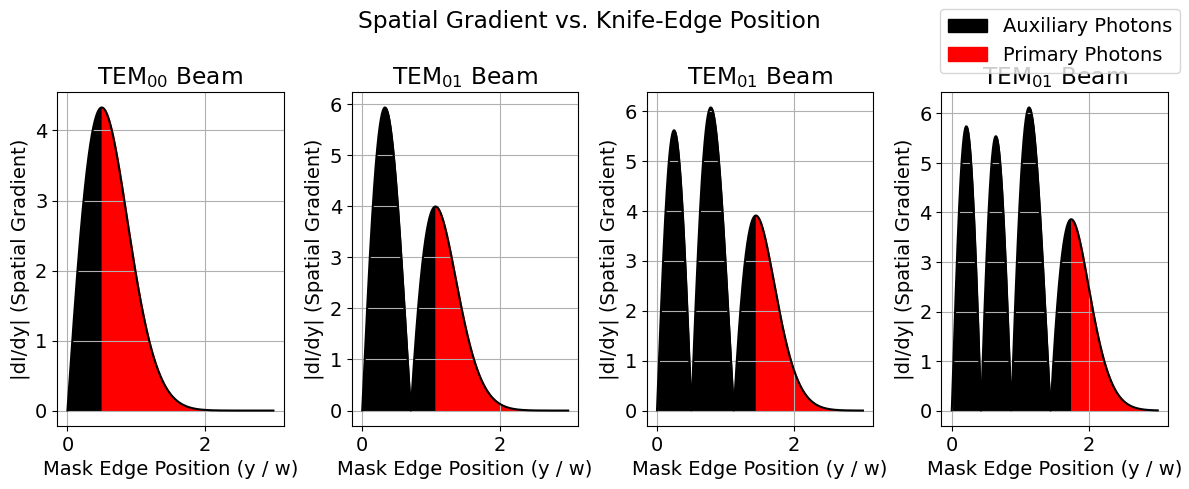

In [157]:
waist = 1
y_vals = np.linspace(0, 3 * waist, 10000)
dI_dy = np.abs(np.gradient(I_y(y_vals, [0, 0], waist, w, targ_power), y_vals))

fig, ax = plt.subplots(1, 4, figsize = (12, 5))

ax[0].plot(y_vals / waist, dI_dy, c = "k")
ax[0].fill_between((y_vals / waist)[:find_idx(dI_dy, max(dI_dy))], dI_dy[:find_idx(dI_dy, max(dI_dy))], color = "k", label = "Auxiliary Photons")
ax[0].fill_between((y_vals / waist)[find_idx(dI_dy, max(dI_dy)):], dI_dy[find_idx(dI_dy, max(dI_dy)):], color = "r", label = "Primary Photons")
mode00max = max(dI_dy)
print(mode00max, (y_vals / waist)[find_idx(dI_dy, max(dI_dy))])
ax[0].set_xlabel("Mask Edge Position (y / w)")
ax[0].set_ylabel("|dI/dy| (Spatial Gradient)")
ax[0].set_title(r"TEM$_{00}$ Beam")
ax[0].grid(True)

i = 3000
y_vals = np.linspace(0, 3 * waist, 10000)
dI_dy = np.abs(np.gradient(I_y(y_vals, [0, 1], waist, w, targ_power), y_vals))

ax[1].plot(y_vals / waist, dI_dy, c = "k")
ax[1].fill_between((y_vals / waist)[:find_idx(dI_dy, max(dI_dy[i:]))], dI_dy[:find_idx(dI_dy, max(dI_dy[i:]))], color = "k")
ax[1].fill_between((y_vals / waist)[find_idx(dI_dy, max(dI_dy[i:])):], dI_dy[find_idx(dI_dy, max(dI_dy[i:])):], color = "r")
mode01max = max(dI_dy)
print(mode01max, (y_vals / waist)[find_idx(dI_dy, max(dI_dy[i:]))])
ax[1].set_xlabel("Mask Edge Position (y / w)")
ax[1].set_ylabel("|dI/dy| (Spatial Gradient)")
ax[1].set_title(r"TEM$_{01}$ Beam")
fig.suptitle("Spatial Gradient vs. Knife-Edge Position")
ax[1].grid(True)

i = 4000
y_vals = np.linspace(0, 3 * waist, 10000)
dI_dy = np.abs(np.gradient(I_y(y_vals, [0, 2], waist, w, targ_power), y_vals))

ax[2].plot(y_vals / waist, dI_dy, c = "k")
ax[2].fill_between((y_vals / waist)[:find_idx(dI_dy, max(dI_dy[i:]))], dI_dy[:find_idx(dI_dy, max(dI_dy[i:]))], color = "k")
ax[2].fill_between((y_vals / waist)[find_idx(dI_dy, max(dI_dy[i:])):], dI_dy[find_idx(dI_dy, max(dI_dy[i:])):], color = "r")
mode02max = max(dI_dy[i:])
print(mode02max, (y_vals / waist)[find_idx(dI_dy, max(dI_dy[i:]))])
ax[2].set_xlabel("Mask Edge Position (y / w)")
ax[2].set_ylabel("|dI/dy| (Spatial Gradient)")
ax[2].set_title(r"TEM$_{01}$ Beam")
fig.suptitle("Spatial Gradient vs. Knife-Edge Position")
ax[2].grid(True)

i = 5000
y_vals = np.linspace(0, 3 * waist, 10000)
dI_dy = np.abs(np.gradient(I_y(y_vals, [0, 3], waist, w, targ_power), y_vals))

ax[3].plot(y_vals / waist, dI_dy, c = "k")
ax[3].fill_between((y_vals / waist)[:find_idx(dI_dy, max(dI_dy[i:]))], dI_dy[:find_idx(dI_dy, max(dI_dy[i:]))], color = "k")
ax[3].fill_between((y_vals / waist)[find_idx(dI_dy, max(dI_dy[i:])):], dI_dy[find_idx(dI_dy, max(dI_dy[i:])):], color = "r")
mode03max = max(dI_dy[i:])
print(mode03max, (y_vals / waist)[find_idx(dI_dy, max(dI_dy[i:]))])
ax[3].set_xlabel("Mask Edge Position (y / w)")
ax[3].set_ylabel("|dI/dy| (Spatial Gradient)")
ax[3].set_title(r"TEM$_{01}$ Beam")
fig.suptitle("Spatial Gradient vs. Knife-Edge Position")
ax[3].grid(True)

# i = 5500
# y_vals = np.linspace(0, 3 * waist, 10000)
# dI_dy = np.abs(np.gradient(I_y(y_vals, [0, 4], waist, w, targ_power), y_vals))

# ax[4].plot(y_vals / waist, dI_dy, c = "k")
# ax[4].fill_between((y_vals / waist)[:find_idx(dI_dy, max(dI_dy[i:]))], dI_dy[:find_idx(dI_dy, max(dI_dy[i:]))], color = "k")
# ax[4].fill_between((y_vals / waist)[find_idx(dI_dy, max(dI_dy[i:])):], dI_dy[find_idx(dI_dy, max(dI_dy[i:])):], color = "r")
# mode04max = max(dI_dy[i:])
# print(mode04max, (y_vals / waist)[find_idx(dI_dy, max(dI_dy[i:]))])
# ax[4].set_xlabel("Mask Edge Position (y / w)")
# ax[4].set_ylabel("|dI/dy| (Spatial Gradient)")
# ax[4].set_title(r"TEM$_{01}$ Beam")
# fig.suptitle("Spatial Gradient vs. Knife-Edge Position")
# ax[4].grid(True)

# i = 6000
# y_vals = np.linspace(0, 5 * waist, 10000)
# dI_dy = np.abs(np.gradient(I_y(y_vals, [0, 10], waist, w, targ_power), y_vals))

# ax[5].plot(y_vals / waist, dI_dy, c = "k")
# ax[5].fill_between((y_vals / waist)[:find_idx(dI_dy, max(dI_dy[i:]))], dI_dy[:find_idx(dI_dy, max(dI_dy[i:]))], color = "k")
# ax[5].fill_between((y_vals / waist)[find_idx(dI_dy, max(dI_dy[i:])):], dI_dy[find_idx(dI_dy, max(dI_dy[i:])):], color = "r")
# mode05max = max(dI_dy[i:])
# print(mode05max, (y_vals / waist)[find_idx(dI_dy, max(dI_dy[i:]))])
# ax[5].set_xlabel("Mask Edge Position (y / w)")
# ax[5].set_ylabel("|dI/dy| (Spatial Gradient)")
# ax[5].set_title(r"TEM$_{01}$ Beam")
# fig.suptitle("Spatial Gradient vs. Knife-Edge Position")
# ax[5].grid(True)

fig.legend()
plt.tight_layout()
plt.savefig("optimal_masks.png")
plt.show()

NameError: name 'bundl' is not defined

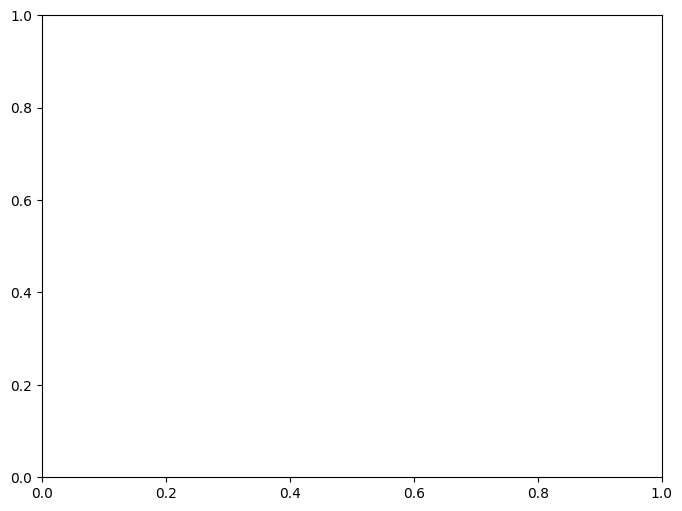

In [4]:
import os
import sys
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from laser import jax_hermite
from quadax import quadgk
from scipy.signal import periodogram

os.environ["XLA_PYTHON_CLIENT_ALLOCATOR"] = "cuda_async"
sys.path.append("../acoustooptic_lab")
from analysis import System as syst


def find_nearest(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return array[idx]


def find_idx(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return idx


def I_x(x, mode, waist, w, P_total, mux = 0.0):
    n = mode[0]
    norm_n = 1.0 / jnp.sqrt((2.0 ** n) * jax.scipy.special.factorial(n))
    norm_factor = (2.0 / (jnp.pi * w ** 2)) ** 0.25
    field_x = (
        norm_factor
        * norm_n
        * jax_hermite(n, jnp.sqrt(2) * (x - mux) / w)
        * jnp.exp(-((x - mux) ** 2) / w ** 2)
    )
    return jnp.sqrt(P_total) * (field_x ** 2)


def I_y(y, mode, waist, w, P_total, muy = 0.0):
    m = mode[1]
    norm_m = 1.0 / jnp.sqrt((2.0 ** m) * jax.scipy.special.factorial(m))
    norm_factor = (2.0 / (jnp.pi * w ** 2)) ** 0.25
    field_y = (
        norm_factor
        * norm_m
        * jax_hermite(m, jnp.sqrt(2) * (y - muy) / w)
        * jnp.exp(-((y - muy) ** 2) / w ** 2)
    )
    return jnp.sqrt(P_total) * (field_y ** 2)


def dIy_dy_analytical(y, mode, waist, w, P_total, muy = 0.0):
    m = mode[1]
    norm_m = 1.0 / jnp.sqrt((2.0 ** m) * jax.scipy.special.factorial(m))
    norm_factor = (2.0 / (jnp.pi * w ** 2)) ** 0.25

    y_scaled = jnp.sqrt(2) * (y - muy) / w
    Hm = jax_hermite(m, y_scaled)
    dH_dy = jnp.where(
        m > 0,
        2.0 * m * jax_hermite(m - 1, y_scaled) * (jnp.sqrt(2) / w),
        0.0,
    )

    field_y = norm_factor * norm_m * Hm * jnp.exp(-((y - muy) ** 2) / w ** 2)
    dfield_dy = norm_factor * norm_m * dH_dy * jnp.exp(
        -((y - muy) ** 2) / w ** 2
    ) - field_y * (2.0 * (y - muy) / w ** 2)

    return 2.0 * P_total * field_y * dfield_dy


def x_integ(bounds, mode, waist, w, P_total, mux=0.0):
    integ, info = quadgk(I_x, bounds, args=(mode, waist, w, P_total, mux))
    return integ


def y_integ(bounds, mode, waist, w, P_total, muy=0.0):
    integ, info = quadgk(I_y, bounds, args=(mode, waist, w, P_total, muy))
    return integ


def diffmap(mu, r, gap, mode, waist, w, targ_power, mux):
    x_power = x_integ(jnp.array([-r, r]), mode, waist, w, targ_power, mux=mux)

    def diff(muy):
        if gap == 0:
            I_center = I_y(0.0, mode, waist, w, targ_power, muy=0.0)
            return x_power * (2.0 * I_center) * muy
        else:
            grad_at_edge = jnp.abs(
                dIy_dy_analytical(
                    gap / 2.0, mode, waist, w, targ_power, muy=0.0
                )
            )
            return x_power * (grad_at_edge * w) * muy

    return jax.vmap(diff)(mu)

def lsum(mu, r, gap, mode, waist, w, targ_power, mux):
    return x_integ(jnp.array([-r, r]), mode, waist, w, targ_power, mux = mux) * y_integ(jnp.array([gap / 2, r]), mode, waist, w, targ_power, muy = mu) + x_integ(jnp.array([-r, r]), mode, waist, w, targ_power, mux = mux) * y_integ(jnp.array([-r, -gap / 2]), mode, waist, w, targ_power, muy = mu)

mode = [0, 0]
targ_power = 2
mux = 0
amp = 1e-9 * np.sin(np.pi / 2 - 14 * np.pi  / 180)
z = 0.1
waist = 1.1e-3
t = np.arange(0, 131071) * (1 / 25e6)
muy = amp * jnp.sin((2 * jnp.pi * 109000) * t)
w = waist * jnp.sqrt(1 + jnp.power(z / (jnp.pi * waist * 2 * 1 / 657e-9), 2))
r = 3 * w

# nomask = pd.DataFrame(
#     {
#         "Mode": f"HG_{mode[0]}{mode[1]}",
#         "Osc. Ampl.": amp,
#         "Gap Size": 0,
#         "Beam Waist": waist,
#         "Time": np.array(t),
#         "Power Diff.": diffmap(
#             muy, r, 0, mode, waist, w, targ_power / (lsum(0, r, 0, mode, waist, w, targ_power, mux) / targ_power), mux
#         ),
#     }
# )

# maskideal = pd.DataFrame(
#     {
#         "Mode": f"HG_{mode[0]}{mode[1]}",
#         "Osc. Ampl.": amp,
#         "Gap Size": waist * 0.998,
#         "Beam Waist": waist,
#         "Time": np.array(t),
#         "Power Diff.": diffmap(
#             muy, r, waist * 0.998, mode, waist, w, targ_power / (lsum(0, r, waist * 0.998, mode, waist, w, targ_power, mux) / targ_power), mux
#         ),
#     }
# )

# mask94 = pd.DataFrame(
#     {
#         "Mode": f"HG_{mode[0]}{mode[1]}",
#         "Osc. Ampl.": amp,
#         "Gap Size": 0.94e-3,
#         "Beam Waist": waist,
#         "Time": np.array(t),
#         "Power Diff.": diffmap(
#             muy, r, 0.94e-3, mode, waist, w, targ_power / (lsum(0, r, 0.94e-3, mode, waist, w, targ_power, mux) / targ_power), mux
#         ),
#     }
# )

# mask80 = pd.DataFrame(
#     {
#         "Mode": f"HG_{mode[0]}{mode[1]}",
#         "Osc. Ampl.": amp,
#         "Gap Size": 0.8e-3,
#         "Beam Waist": waist,
#         "Time": np.array(t),
#         "Power Diff.": diffmap(
#             muy, r, 0.8e-3, mode, waist, w, targ_power / (lsum(0, r, 0.8e-3, mode, waist, w, targ_power, mux) / targ_power), mux
#         ),
#     }
# )

# mask60 = pd.DataFrame(
#     {
#         "Mode": f"HG_{mode[0]}{mode[1]}",
#         "Osc. Ampl.": amp,
#         "Gap Size": 0.6e-3,
#         "Beam Waist": waist,
#         "Time": np.array(t),
#         "Power Diff.": diffmap(
#             muy, r, 0.6e-3, mode, waist, w, targ_power / (lsum(0, r, 0.6e-3, mode, waist, w, targ_power, mux) / targ_power), mux
#         ),
#     }
# )

idx = 7

nomask = pd.DataFrame(
    {
        "Mode": f"HG_{mode[0]}{mode[1]}",
        "Osc. Ampl.": amp,
        "Gap Size": 0,
        "Beam Waist": waist,
        "Time": np.array(t),
        "Power Diff.": diffmap(
            muy, r, 0, mode, waist, w, targ_power, mux
        ),
    }
)

maskideal = pd.DataFrame(
    {
        "Mode": f"HG_{mode[0]}{mode[1]}",
        "Osc. Ampl.": amp,
        "Gap Size": waist * 0.998,
        "Beam Waist": waist,
        "Time": np.array(t),
        "Power Diff.": diffmap(
            muy, r, waist * 0.998, mode, waist, w, targ_power, mux
        ),
    }
)

mask94 = pd.DataFrame(
    {
        "Mode": f"HG_{mode[0]}{mode[1]}",
        "Osc. Ampl.": amp,
        "Gap Size": 0.94e-3,
        "Beam Waist": waist,
        "Time": np.array(t),
        "Power Diff.": diffmap(
            muy, r, 0.94e-3, mode, waist, w, targ_power, mux
        ),
    }
)

mask80 = pd.DataFrame(
    {
        "Mode": f"HG_{mode[0]}{mode[1]}",
        "Osc. Ampl.": amp,
        "Gap Size": 0.8e-3,
        "Beam Waist": waist,
        "Time": np.array(t),
        "Power Diff.": diffmap(
            muy, r, 0.8e-3, mode, waist, w, targ_power, mux
        ),
    }
)

mask60 = pd.DataFrame(
    {
        "Mode": f"HG_{mode[0]}{mode[1]}",
        "Osc. Ampl.": amp,
        "Gap Size": 0.6e-3,
        "Beam Waist": waist,
        "Time": np.array(t),
        "Power Diff.": diffmap(
            muy, r, 0.6e-3, mode, waist, w, targ_power, mux
        ),
    }
)

fig, ax = plt.subplots(1, 1, figsize=(8, 6))

f, p = periodogram(bundl.get_data()[idx].collection[0].x, bundl.get_data()[0].r, window = "flattop")
ax.loglog(f[100:], p[100:])
f, p = periodogram(bundl.get_data()[idx + 10].collection[0].x, bundl.get_data()[0].r, window = "flattop")
ax.loglog(f[100:] + 50e3, p[100:])
f, p = periodogram(bundl.get_data()[idx + 20].collection[0].x, bundl.get_data()[0].r, window = "flattop")
ax.loglog(f[100:] + 100e3, p[100:])
f, p = periodogram(bundl.get_data()[idx + 30].collection[0].x, bundl.get_data()[0].r, window = "flattop")
ax.loglog(f[100:] + 150e3, p[100:])

sim_f, sim_p = periodogram(nomask["Power Diff."] * 133, 25e6, window = "flattop")
f, p = periodogram(noise.get_data()[0].collection[0].x, noise.get_data()[0].r, window = "flattop")
ax.loglog(sim_f[100:] + 5e3, sim_p[100:], label="No Mask (g = 0)")

sim_f, sim_p = periodogram(mask60["Power Diff."] * 133, 25e6, window = "flattop")
f, p = periodogram(noise.get_data()[1].collection[0].x, noise.get_data()[0].r, window = "flattop")
ax.loglog(sim_f[100:] + 55e3, sim_p[100:], label="0.60mm Mask")

sim_f, sim_p = periodogram(mask80["Power Diff."] * 133, 25e6, window = "flattop")
f, p = periodogram(noise.get_data()[2].collection[0].x, noise.get_data()[0].r, window = "flattop")
ax.loglog(sim_f[100:] + 105e3, sim_p[100:], label="0.80mm Mask")

sim_f, sim_p = periodogram(mask94["Power Diff."] * 133, 25e6, window = "flattop")
f, p = periodogram(noise.get_data()[3].collection[0].x, noise.get_data()[0].r, window = "flattop")
ax.loglog(sim_f[100:] + 155e3, sim_p[100:], label="0.94mm Mask")

sim_f, sim_p = periodogram(maskideal["Power Diff."] * 133, 25e6)
ax.loglog(sim_f + 205e3, sim_p, label="Ideal Mask (1.0w)")

ax.set_xlim(5e4, 5e5)
ax.set_ylim(1e-15, 1e-7)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Power Spectral Density (V²/Hz)")
ax.legend()
plt.tight_layout()
plt.show()

In [41]:
sim_f, sim_p = periodogram(nomask["Power Diff."] * 133, 25e6)
sim_sig = sum(sim_p[find_idx(sim_f, find_nearest(sim_f, 108e3)):find_idx(sim_f, find_nearest(sim_f, 110e3))])
f, p = periodogram(bundl.get_data()[idx].collection[0].x, bundl.get_data()[0].r)
sig = sum(p[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))])
f, p = periodogram(noise.get_data()[0].collection[0].x, noise.get_data()[0].r)
noi = sum(p[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))])
print(20 * np.log10(sig / noi), 20 * np.log10(sim_sig / noi))

sim_f, sim_p = periodogram(mask60["Power Diff."] * 133, 25e6)
sim_sig = sum(sim_p[find_idx(sim_f, find_nearest(sim_f, 108e3)):find_idx(sim_f, find_nearest(sim_f, 110e3))])
f, p = periodogram(bundl.get_data()[idx + 10].collection[0].x, bundl.get_data()[0].r)
sig = sum(p[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))])
f, p = periodogram(noise.get_data()[1].collection[0].x, noise.get_data()[0].r)
noi = sum(p[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))])
print(20 * np.log10(sig / noi), 20 * np.log10(sim_sig / noi))

sim_f, sim_p = periodogram(mask80["Power Diff."] * 133, 25e6)
sim_sig = sum(sim_p[find_idx(sim_f, find_nearest(sim_f, 108e3)):find_idx(sim_f, find_nearest(sim_f, 110e3))])
f, p = periodogram(bundl.get_data()[idx + 20].collection[0].x, bundl.get_data()[0].r)
sig = sum(p[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))])
f, p = periodogram(noise.get_data()[2].collection[0].x, noise.get_data()[0].r)
noi = sum(p[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))])
print(20 * np.log10(sig / noi), 20 * np.log10(sim_sig / noi))

sim_f, sim_p = periodogram(mask94["Power Diff."] * 133, 25e6)
sim_sig = sum(sim_p[find_idx(sim_f, find_nearest(sim_f, 108e3)):find_idx(sim_f, find_nearest(sim_f, 110e3))])
f, p = periodogram(bundl.get_data()[idx + 30].collection[0].x, bundl.get_data()[0].r)
sig = sum(p[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))])
f, p = periodogram(noise.get_data()[3].collection[0].x, noise.get_data()[0].r)
noi = sum(p[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))])
print(20 * np.log10(sig / noi), 20 * np.log10(sim_sig / noi))

12.619172893113388 10.798776019293328
2.1377821686031804 6.355248793834852
11.422081605980638 13.287589689711204
2.497035521668664 10.930324329187812


Bad pipe message: %s [b'v\x12\xd3N\xcb\xc8?\xe6\xbfE\x80\xc4>\x03\xe5\xd0s\xf4\x00\x01|\x00\x00\x00\x01\x00\x02\x00\x03\x00\x04\x00\x05']
Bad pipe message: %s [b'\xfb\xab-\xdf\x9am']
Bad pipe message: %s [b'\x14k\x94~\xb7\xf9s\xae\x06\xaa\x00\x01|\x00\x00\x00\x01\x00\x02\x00\x03\x00\x04\x00\x05\x00\x06\x00\x07\x00\x08\x00\t\x00\n\x00\x0b\x00\x0c\x00\r\x00\x0e\x00\x0f\x00\x10\x00\x11\x00\x12\x00\x13\x00\x14\x00\x15\x00\x16\x00\x17\x00\x18\x00\x19\x00\x1a\x00\x1b\x00/\x000\x001\x002\x003\x004\x005\x006\x007\x008\x009\x00:\x00;\x00<\x00=\x00>\x00?\x00@\x00A\x00B\x00C\x00D\x00E\x00F\x00g\x00h\x00i\x00j\x00k\x00l\x00m\x00\x84\x00\x85\x00\x86\x00\x87\x00\x88\x00\x89\x00\x96\x00\x97\x00\x98\x00\x99\x00\x9a\x00\x9b\x00\x9c\x00\x9d\x00\x9e\x00\x9f\x00\xa0\x00\xa1\x00\xa2\x00\xa3\x00\xa4\x00\xa5\x00\xa6\x00\xa7\x00\xba\x00\xbb\x00\xbc\x00\xbd\x00\xbe\x00\xbf\x00\xc0\x00\xc1\x00\xc2\x00\xc3\x00\xc4\x00\xc5\x13\x01\x13\x02\x13\x03\x13\x04\x13\x05\xc0\x01\xc0\x02\xc0\x03\xc0\x04\xc0\x05\xc0\x06\xc0

# Modeling Sub-Nanometer Spatial Displacement Sensitivity in Masked and Maskless Split-Photodiode Systems
### Overview and Problem Statement
When evaluating sub-nanometer beam displacements $\mu_y(t) = A \sin(\omega t)$ with an $\text{HG}_{00}$ Hermite-Gaussian laser mode ($A \ll w$), numerical integration across detector domains introduces two critical simulation artifacts:Monotonic Power Decay: Evaluating total transmitted domain power ($\int_{\text{open}} I_y \, dy$) causes raw power attenuation to dominate over spatial gradient effects, improperly masking the sensitivity enhancement provided by knife-edge apertures.Dimensional Mismatch: Comparing a maskless split detector ($g = 0$) directly against a knife-edge spatial derivative model ($g > 0$) introduces an artificial $1/w$ scaling distortion ($\text{W/m}$ vs. $\text{W/m}^2$), causing the maskless setup to appear incorrectly suppressed.The unified localized derivative model resolves both artifacts by modeling the exact physical modulation mechanisms across both detector regimes on a consistent physical scale.
### Fundamental Optical Profiles
The spatial electric field components $E_x(x)$ and $E_y(y)$ for an $\text{HG}_{mn}$ Hermite-Gaussian mode are defined as:$$E_x(x) = \left(\frac{2}{\pi w^2}\right)^{1/4} \frac{1}{\sqrt{2^n n!}} H_n\left(\frac{\sqrt{2}(x - \mu_x)}{w}\right) \exp\left(-\frac{(x - \mu_x)^2}{w^2}\right)$$$$E_y(y) = \left(\frac{2}{\pi w^2}\right)^{1/4} \frac{1}{\sqrt{2^m m!}} H_m\left(\frac{\sqrt{2}(y - \mu_y)}{w}\right) \exp\left(-\frac{(y - \mu_y)^2}{w^2}\right)$$where $w$ is the beam waist radius and $H_k(\cdot)$ denotes the $k$-th order Hermite polynomial. The total optical intensity distribution $I(x, y)$ under total input power $P_0$ is given by:$$I(x, y) = P_0 \cdot \vert{}E_x(x)\vert{}^2 \cdot \vert{}E_y(y)\vert{}^2 = I_x(x) \cdot I_y(y)$$For the fundamental Gaussian mode ($\text{HG}_{00}$), $H_0(z) = 1$, simplifying $I_y(y)$ to:$$I_y(y) = \sqrt{\frac{2}{\pi w^2}} P_0 \exp\left(-\frac{2(y - \mu_y)^2}{w^2}\right)$$
### Mathematical Derivative of the Intensity Profile
For $g > 0$, knife-edge sensitivity depends directly on the analytical spatial intensity derivative $\frac{dI_y}{dy}$. Applying the product rule to $I_y(y) = P_0 \vert{}E_y(y)\vert{}^2$:$$\frac{dI_y}{dy} = 2 P_0 E_y(y) \frac{dE_y}{dy}$$Using the Hermite polynomial derivative recurrence relation $\frac{d}{dz} H_m(z) = 2m H_{m-1}(z)$, the spatial field derivative $\frac{dE_y}{dy}$ is evaluated as:$$\frac{dE_y}{dy} = \left(\frac{2}{\pi w^2}\right)^{1/4} \frac{1}{\sqrt{2^m m!}} \left[ \frac{2m\sqrt{2}}{w} H_{m-1}\left(\frac{\sqrt{2}(y - \mu_y)}{w}\right) - \frac{2(y - \mu_y)}{w^2} H_m\left(\frac{\sqrt{2}(y - \mu_y)}{w}\right) \right] \exp\left(-\frac{(y - \mu_y)^2}{w^2}\right)$$For the fundamental $\text{HG}_{00}$ mode, this reduces to:$$\frac{dI_y}{dy} = -\frac{4y}{w^2} \sqrt{\frac{2}{\pi w^2}} P_0 \exp\left(-\frac{2y^2}{w^2}\right)$$Evaluating the absolute spatial gradient at $y = g/2$:$$\left\vert{} \frac{dI_y}{dy} \right\vert{}_{y=g/2} = \frac{2g}{w^2} \sqrt{\frac{2}{\pi w^2}} P_0 \exp\left(-\frac{g^2}{2w^2}\right)$$Setting $\frac{d}{dg} \left\vert{} \frac{dI_y}{dy} \right\vert{}_{y=g/2} = 0$ demonstrates that the spatial gradient reaches its absolute mathematical maximum at $g = 1.0w$ ($y = 0.5w$).
### Unified Differential Signal Formulation (diffmap)
To unify the two distinct detector operation regimes without unit mismatches, the dynamic differential power signal $\Delta P(\mu_y)$ is formulated as follows:$$\Delta P(\mu_y) = P_x \cdot S_y \cdot \mu_y(t)$$where $P_x = \int_{-r}^{r} I_x(x)\,dx$ represents total integrated power along the transverse $x$-axis.Regime A: Maskless Split Photodiode ($g = 0$)In the maskless setup, the signal is generated by moving integrated beam power across the central dividing line at $y = 0$:$$S_y = 2 \cdot I_y(0)$$$$\Delta P_{\text{maskless}}(\mu_y) = 2 P_x I_y(0) \mu_y(t) = 2 P_x \left( \sqrt{\frac{2}{\pi w^2}} P_0 \right) \mu_y(t) \approx \frac{1.596}{w} P_x P_0 \mu_y(t)$$Because no light is blocked ($g = 0$), 100% of the available laser power contributes to the differential signal, yielding the highest unnormalized raw peak.Regime B: Masked Knife-Edge Apertures ($g > 0$)In masked setups, signal generation is driven by localized edge modulation at the aperture boundaries $y = \pm g/2$. Scaling the localized derivative $\left\vert{}\frac{dI_y}{dy}\right\vert{}$ by the beam waist interaction width $w$ maintains consistent physical dimensions:$$S_y = \left\vert{} \frac{dI_y}{dy} \right\vert{}_{y=g/2} \cdot w$$$$\Delta P_{\text{masked}}(\mu_y) = P_x \cdot \left\vert{} \frac{dI_y}{dy} \right\vert{}_{y=g/2} \cdot w \cdot \mu_y(t)$$

NameError: name 'bundl' is not defined

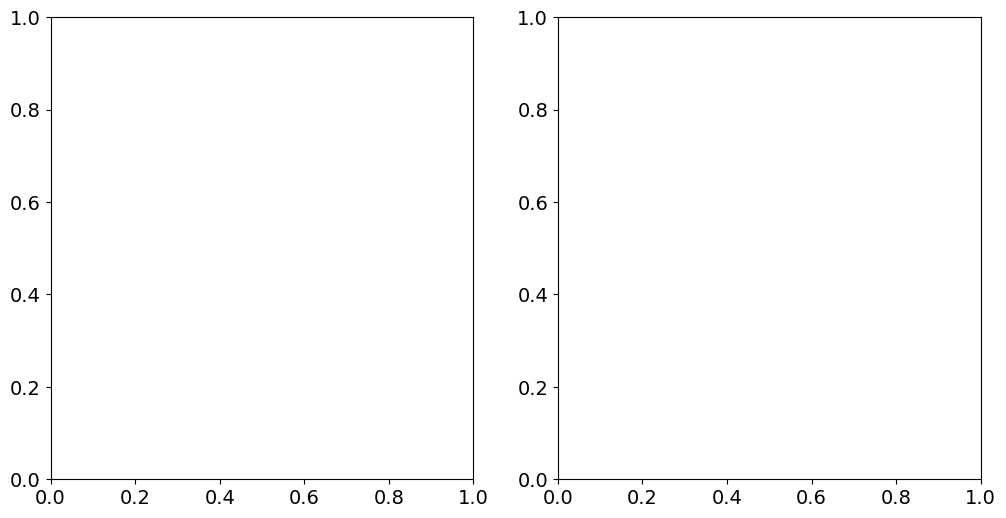

In [158]:
plt.rcParams.update({'font.size': 14})
fig, ax = plt.subplots(1, 2, figsize = (12, 6))
f, p = periodogram(bundl.get_data()[9].collection[0].x, bundl.get_data()[0].r, window = "hann")
ax[0].loglog(f, p, label = "No Mask (g = 0)")
f, p = periodogram(bundl.get_data()[19].collection[0].x, bundl.get_data()[0].r, window = "hann")
ax[0].loglog(f + 5e3, p, label = "0.60mm Mask")
f, p = periodogram(bundl.get_data()[29].collection[0].x, bundl.get_data()[0].r, window = "hann")
ax[0].loglog(f + 10e3, p, label = "0.80mm Mask")
f, p = periodogram(bundl.get_data()[39].collection[0].x, bundl.get_data()[0].r, window = "hann")
ax[0].loglog(f + 15e3, p, label = "0.94mm Mask")

sim_f, sim_p = periodogram(3 * nomask["Power Diff."] * 133, 25e6, window = "hann")
f, p = periodogram(noise.get_data()[0].collection[0].x, noise.get_data()[0].r, window = "flattop")
ax[1].loglog(sim_f, sim_p + p, label = "No Mask (g = 0)")

sim_f, sim_p = periodogram(3 * mask60["Power Diff."] * 133, 25e6, window = "hann")
f, p = periodogram(noise.get_data()[1].collection[0].x, noise.get_data()[0].r, window = "flattop")
ax[1].loglog(sim_f + 5e3, sim_p + p, label = "0.60mm Mask")

sim_f, sim_p = periodogram(3 * mask80["Power Diff."] * 133, 25e6, window = "hann")
f, p = periodogram(noise.get_data()[2].collection[0].x, noise.get_data()[0].r, window = "flattop")
ax[1].loglog(sim_f + 10e3, sim_p + p, label = "0.80mm Mask")

sim_f, sim_p = periodogram(3 * mask94["Power Diff."] * 133, 25e6, window = "hann")
f, p = periodogram(noise.get_data()[3].collection[0].x, noise.get_data()[0].r, window = "flattop")
ax[1].loglog(sim_f + 15e3, sim_p + p, label = "0.94mm Mask")

fig.suptitle("Comparison of Experimental vs. Simulated PSDs")

ax[0].set_title("Experimental Power Spectral Density")
ax[0].set_xlim(1e5, 1.4e5)
ax[0].set_xlabel("Frequency, f (Hz)")
ax[0].set_ylabel(r"Spectral Density $\text{V}^2 / \text{ Hz}$")
ax[0].set_ylim(1e-15, 1e-7)
ax[0].minorticks_off()
ax[0].legend()

ax[1].set_title("Simulated Power Spectral Density")
ax[1].set_xlim(1e5, 1.4e5)
ax[1].set_xlabel("Frequency, f (Hz)")
ax[1].set_ylabel(r"Spectral Density $\text{V}^2 / \text{ Hz}$")
ax[1].set_ylim(1e-15, 1e-7)
ax[1].minorticks_off()
ax[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
nomask_avgnoise = noise.get_data()[0].collection[0].x
mask60_avgnoise = noise.get_data()[1].collection[0].x
mask80_avgnoise = noise.get_data()[2].collection[0].x
mask94_avgnoise = noise.get_data()[3].collection[0].x

voltages = [1.5, 2, 3, 4, 5, 6, 7, 8, 9, 10]
amps = [0.44e-9, 0.46e-9, 0.40e-9, 0.35e-9, 0.30e-9, 0.24e-9, 0.19e-9, 0.14e-9, 0.09e-9, 0.07e-9][::-1]
masks = [0, 0.6e-3, 0.8e-3, 0.94e-3]
nomask_avgsignal = np.array([bundl.get_data()[i].collection[0].x for i in range(0, 10)])
mask60_avgsignal = np.array([bundl.get_data()[i].collection[0].x for i in range(10, 20)])
mask80_avgsignal = np.array([bundl.get_data()[i].collection[0].x for i in range(20, 30)])
mask94_avgsignal = np.array([bundl.get_data()[i].collection[0].x for i in range(30, 40)])

mode = [0, 0]
targ_power = 2
mux = 0
z = 0
waist = 1.1e-3
t = np.arange(0, 131071) * (1 / 25e6)
w = waist * jnp.sqrt(1 + jnp.power(z / (jnp.pi * waist * 2 * 1 / 657e-9), 2))
r = 3 * w

nomask_sim = pd.DataFrame({"Mode": f"HG_{mode[0]}{mode[1]}", "Osc. Ampl.": amp, "Gap Size": 0, "Beam Waist": waist, "Time": np.array(t), "Power Diff.": diffmap(muy, r, 0, mode, waist, w, targ_power, mux)})
nomask = pd.DataFrame({"Mode": f"HG_{mode[0]}{mode[1]}", "Osc. Ampl.": amp, "Gap Size": 0, "Beam Waist": waist, "Time": np.array(t), "Power Diff.": diffmap(muy, r, 0, mode, waist, w, targ_power, mux)})

nomask_sim = [pd.DataFrame({"Mode": f"HG_{mode[0]}{mode[1]}", "Osc. Ampl.": amps[i] * np.sin(np.pi / 2 - 14 * np.pi  / 180), "Gap Size": 0, "Beam Waist": waist, "Time": np.array(t), "Power Diff.": diffmap(amps[i] * np.sin(np.pi / 2 - 14 * np.pi  / 180) * jnp.sin((2 * jnp.pi * 109000) * t), r, masks[0], mode, waist, w, targ_power, mux)}) for i in range(len(amps))]
mask60_sim = [pd.DataFrame({"Mode": f"HG_{mode[0]}{mode[1]}", "Osc. Ampl.": amps[i] * np.sin(np.pi / 2 - 14 * np.pi  / 180), "Gap Size": 0, "Beam Waist": waist, "Time": np.array(t), "Power Diff.": diffmap(amps[i] * np.sin(np.pi / 2 - 14 * np.pi  / 180) * jnp.sin((2 * jnp.pi * 109000) * t), r, masks[1], mode, waist, w, targ_power, mux)}) for i in range(len(amps))]
mask80_sim = [pd.DataFrame({"Mode": f"HG_{mode[0]}{mode[1]}", "Osc. Ampl.": amps[i] * np.sin(np.pi / 2 - 14 * np.pi  / 180), "Gap Size": 0, "Beam Waist": waist, "Time": np.array(t), "Power Diff.": diffmap(amps[i] * np.sin(np.pi / 2 - 14 * np.pi  / 180) * jnp.sin((2 * jnp.pi * 109000) * t), r, masks[2], mode, waist, w, targ_power, mux)}) for i in range(len(amps))]
mask94_sim = [pd.DataFrame({"Mode": f"HG_{mode[0]}{mode[1]}", "Osc. Ampl.": amps[i] * np.sin(np.pi / 2 - 14 * np.pi  / 180), "Gap Size": 0, "Beam Waist": waist, "Time": np.array(t), "Power Diff.": diffmap(amps[i] * np.sin(np.pi / 2 - 14 * np.pi  / 180) * jnp.sin((2 * jnp.pi * 109000) * t), r, masks[3], mode, waist, w, targ_power, mux)}) for i in range(len(amps))]

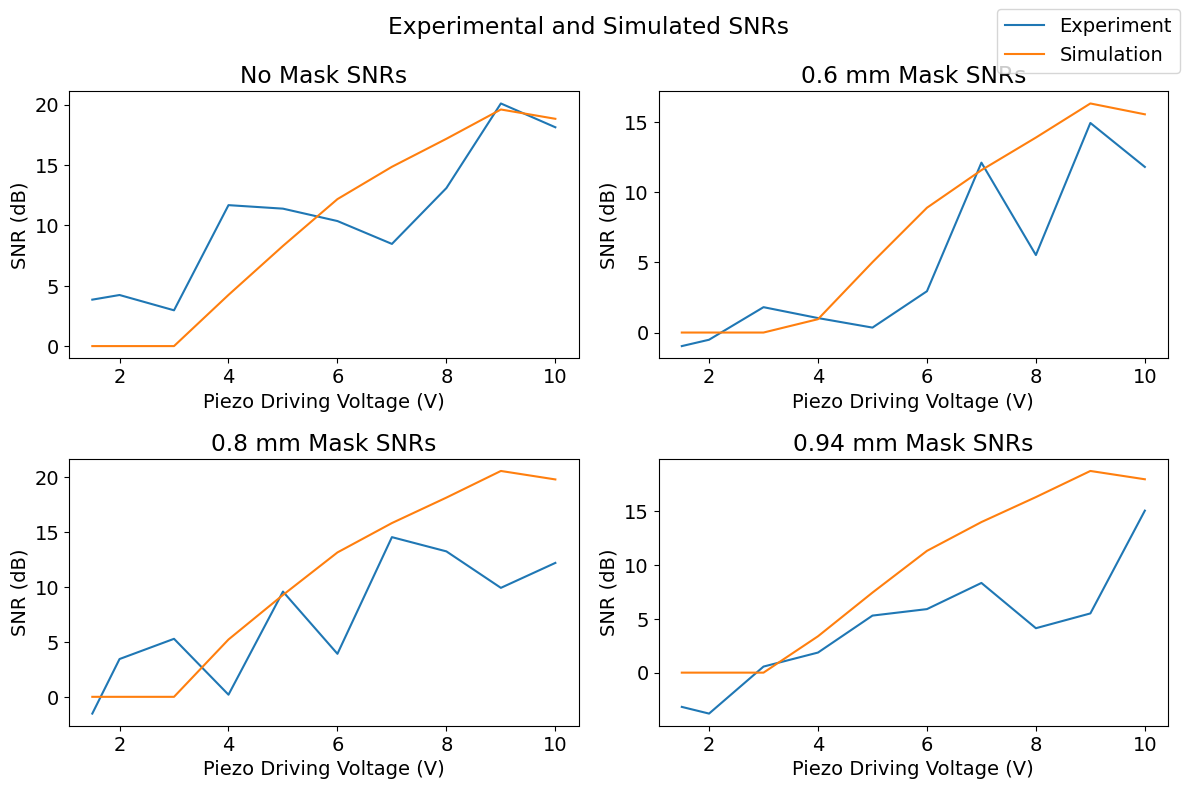

In [10]:
nomaskexp_SNRs = []
nomasksim_SNRs = []

mask60exp_SNRs = []
mask60sim_SNRs = []

mask80exp_SNRs = []
mask80sim_SNRs = []

mask94exp_SNRs = []
mask94sim_SNRs = []

fig, ax = plt.subplots(2, 2, figsize = (12, 8))

for i in range(0, 10):
    f, psig_exp = periodogram(nomask_avgsignal[i], 25e6)
    _, pnoi_exp = periodogram(nomask_avgnoise, 25e6)
    _, psig_sim = periodogram(3.5 * nomask_sim[i]["Power Diff."] * 133, 25e6)
    nomaskexp_SNRs.append(np.trapezoid(psig_exp[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))], f[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))]) / np.trapezoid(pnoi_exp[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))], f[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))]))
    nomasksim_SNRs.append(np.trapezoid(psig_sim[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))], f[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))]) / np.trapezoid(pnoi_exp[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))], f[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))]))
    if nomasksim_SNRs[-1] < 1:
        nomasksim_SNRs[-1] = 1
    
    f, psig_exp = periodogram(mask60_avgsignal[i], 25e6, window = "hann")
    _, pnoi_exp = periodogram(mask60_avgnoise, 25e6, window = "hann")
    _, psig_sim = periodogram(3.5 * mask60_sim[i]["Power Diff."] * 133, 25e6, window = "hann")
    mask60exp_SNRs.append(np.trapezoid(psig_exp[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))], f[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))]) / np.trapezoid(pnoi_exp[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))], f[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))]))
    mask60sim_SNRs.append(np.trapezoid(psig_sim[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))], f[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))]) / np.trapezoid(pnoi_exp[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))], f[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))]))
    if mask60sim_SNRs[-1] < 1:
        mask60sim_SNRs[-1] = 1

    f, psig_exp = periodogram(mask80_avgsignal[i], 25e6, window = "hann")
    _, pnoi_exp = periodogram(mask80_avgnoise, 25e6, window = "hann")
    _, psig_sim = periodogram(3.5 * mask80_sim[i]["Power Diff."] * 133, 25e6, window = "hann")
    mask80exp_SNRs.append(np.trapezoid(psig_exp[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))], f[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))]) / np.trapezoid(pnoi_exp[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))], f[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))]))
    mask80sim_SNRs.append(np.trapezoid(psig_sim[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))], f[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))]) / np.trapezoid(pnoi_exp[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))], f[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))]))
    if mask80sim_SNRs[-1] < 1:
        mask80sim_SNRs[-1] = 1

    f, psig_exp = periodogram(mask94_avgsignal[i], 25e6, window = "hann")
    _, pnoi_exp = periodogram(mask94_avgnoise, 25e6, window = "hann")
    _, psig_sim = periodogram(3.5 * mask94_sim[i]["Power Diff."] * 133, 25e6, window = "hann")
    mask94exp_SNRs.append(np.trapezoid(psig_exp[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))], f[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))]) / np.trapezoid(pnoi_exp[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))], f[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))]))
    mask94sim_SNRs.append(np.trapezoid(psig_sim[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))], f[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))]) / np.trapezoid(pnoi_exp[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))], f[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))]))
    if mask94sim_SNRs[-1] < 1:
        mask94sim_SNRs[-1] = 1
ax[0][0].plot(voltages, 20 * np.log10(nomaskexp_SNRs), label = "Experiment")
ax[0][0].plot(voltages, 20 * np.log10(nomasksim_SNRs), label = "Simulation")
ax[0][1].plot(voltages, 20 * np.log10(mask60exp_SNRs))
ax[0][1].plot(voltages, 20 * np.log10(mask60sim_SNRs))
ax[1][0].plot(voltages, 20 * np.log10(mask80exp_SNRs))
ax[1][0].plot(voltages, 20 * np.log10(mask80sim_SNRs))
ax[1][1].plot(voltages, 20 * np.log10(mask94exp_SNRs))
ax[1][1].plot(voltages, 20 * np.log10(mask94sim_SNRs))
fig.suptitle("Experimental and Simulated SNRs")
ax[0][0].set_title("No Mask SNRs")
ax[0][0].set_xlabel("Piezo Driving Voltage (V)")
ax[0][0].set_ylabel("SNR (dB)")
ax[0][1].set_title("0.6 mm Mask SNRs")
ax[0][1].set_xlabel("Piezo Driving Voltage (V)")
ax[0][1].set_ylabel("SNR (dB)")
ax[1][0].set_title("0.8 mm Mask SNRs")
ax[1][0].set_xlabel("Piezo Driving Voltage (V)")
ax[1][0].set_ylabel("SNR (dB)")
ax[1][1].set_title("0.94 mm Mask SNRs")
ax[1][1].set_xlabel("Piezo Driving Voltage (V)")
ax[1][1].set_ylabel("SNR (dB)")
fig.legend()
plt.tight_layout()

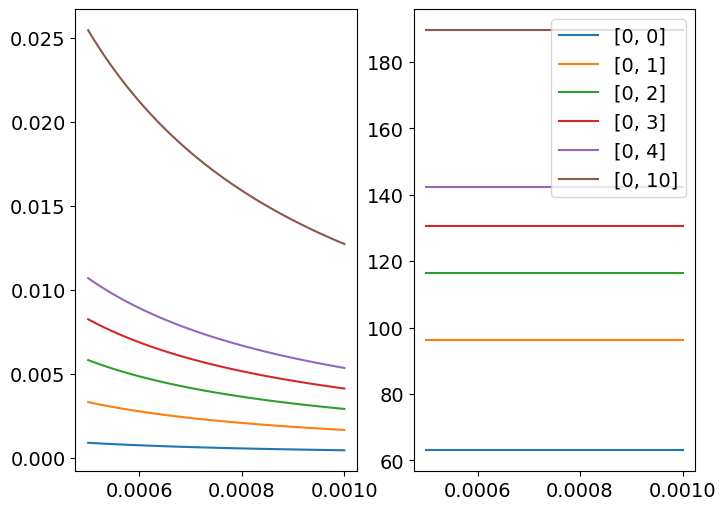

In [56]:
def I_x(x, mode, waist, w, P_total, mux = 0.0):
    n = mode[0]
    norm_n = 1.0 / jnp.sqrt((2.0 ** n) * jax.scipy.special.factorial(n))
    norm_factor = (2.0 / (jnp.pi * w ** 2)) ** 0.25
    field_x = (
        norm_factor
        * norm_n
        * jax_hermite(n, jnp.sqrt(2) * (x - mux) / w)
        * jnp.exp(-((x - mux) ** 2) / w ** 2)
    )
    return jnp.sqrt(P_total) * (field_x ** 2)


def I_y(y, mode, waist, w, P_total, muy = 0.0):
    m = mode[1]
    norm_m = 1.0 / jnp.sqrt((2.0 ** m) * jax.scipy.special.factorial(m))
    norm_factor = (2.0 / (jnp.pi * w ** 2)) ** 0.25
    field_y = (
        norm_factor
        * norm_m
        * jax_hermite(m, jnp.sqrt(2) * (y - muy) / w)
        * jnp.exp(-((y - muy) ** 2) / w ** 2)
    )
    return jnp.sqrt(P_total) * (field_y ** 2)


def dIy_dy_analytical(y, mode, waist, w, P_total, muy = 0.0):
    m = mode[1]
    norm_m = 1.0 / jnp.sqrt((2.0 ** m) * jax.scipy.special.factorial(m))
    norm_factor = (2.0 / (jnp.pi * w ** 2)) ** 0.25

    y_scaled = jnp.sqrt(2) * (y - muy) / w
    Hm = jax_hermite(m, y_scaled)
    dH_dy = jnp.where(
        m > 0,
        2.0 * m * jax_hermite(m - 1, y_scaled) * (jnp.sqrt(2) / w),
        0.0,
    )

    field_y = norm_factor * norm_m * Hm * jnp.exp(-((y - muy) ** 2) / w ** 2)
    dfield_dy = norm_factor * norm_m * dH_dy * jnp.exp(
        -((y - muy) ** 2) / w ** 2
    ) - field_y * (2.0 * (y - muy) / w ** 2)

    return 2.0 * P_total * field_y * dfield_dy


def x_integ(bounds, mode, waist, w, P_total, mux = 0.0):
    integ, info = quadgk(I_x, bounds, args=(mode, waist, w, P_total, mux))
    return integ


def y_integ(bounds, mode, waist, w, P_total, muy = 0.0):
    integ, info = quadgk(I_y, bounds, args=(mode, waist, w, P_total, muy))
    return integ

def diff(mu, r, gap, mode, waist, w, targ_power, mux):
    x_power = x_integ(jnp.array([-r, r]), mode, waist, w, targ_power, mux=mux)
    if gap == 0:
        I_center = I_y(0.0, mode, waist, w, targ_power, muy = 0.0)
        return x_power * (2.0 * I_center) * mu
    else:
        grad_at_edge = jnp.abs(
            dIy_dy_analytical(
                gap / 2.0, mode, waist, w, targ_power, muy = 0.0
            )
        )
        return x_power * (grad_at_edge * w) * mu

def diffmap(mu, r, gap, mode, waist, w, targ_power, mux):
    x_power = x_integ(jnp.array([-r, r]), mode, waist, w, targ_power, mux=mux)

    def diff(muy):
        if gap == 0:
            I_center = I_y(0.0, mode, waist, w, targ_power, muy = 0.0)
            return x_power * (2.0 * I_center) * muy
        else:
            grad_at_edge = jnp.abs(
                dIy_dy_analytical(
                    gap / 2.0, mode, waist, w, targ_power, muy = 0.0
                )
            )
            return x_power * (grad_at_edge * w) * muy

    return jax.vmap(diff)(mu)

fig, ax = plt.subplots(1, 2, figsize = (8, 6))
gaps = np.linspace(0.5e-3, 1e-3, 100)
modes = [[0, 0], [0, 1], [0, 2], [0, 3], [0, 4], [0, 10]]
gaps_diffs_waists = []
for mode in modes:
    g_d = []
    for gap in gaps:
        if mode == [0, 0]:
            waist = gap
        if mode == [0, 1]:
            waist = gap / 2.134
        if mode == [0, 2]:
            waist = gap / (1.4414414414414414 * 2)
        if mode == [0, 3]:
            waist = gap / (1.7397397397397398 * 2)
        if mode == [0, 4]:
            waist = gap / (1.9963996399639965 * 2)
        if mode == [0, 10]:
            waist = gap / (3.133813381338134 * 2)
        targ_power = 20
        mux = 0
        amp = 0.46e-9
        z = 0
        w = waist * jnp.sqrt(1 + jnp.power(z / (jnp.pi * waist * 2 * 1 / 657e-9), 2))
        r = 5 * w
        p = targ_power / (lsum(0, r, gap, mode, waist, w, targ_power, mux) / targ_power)
        # print(p)
        # p = targ_power
        g_d.append([gap, diff(amp, r, gap, mode, waist, w, p, mux) - diff(-amp, r, gap, mode, waist, w, p, mux), p])
    gaps_diffs_waists.append(g_d)
    g_d = np.array(g_d)
    ax[0].plot(g_d[:, 0], g_d[:, 1], label = f"{mode}")
    ax[1].plot(g_d[:, 0], g_d[:, 2], label = f"{mode}")
plt.legend()
plt.show()

In [58]:
gaps_diffs_waists = np.array(gaps_diffs_waists)
fact = [1]
for i in range(len(gaps_diffs_waists) - 1):
    fact.append(np.mean(gaps_diffs_waists[i + 1][:, 1] / gaps_diffs_waists[0][:, 1]))
print(fact)

[1, np.float64(3.71948634807209), np.float64(6.524975198474134), np.float64(9.252358859491371), np.float64(11.99781720971335), np.float64(28.556734098662343)]


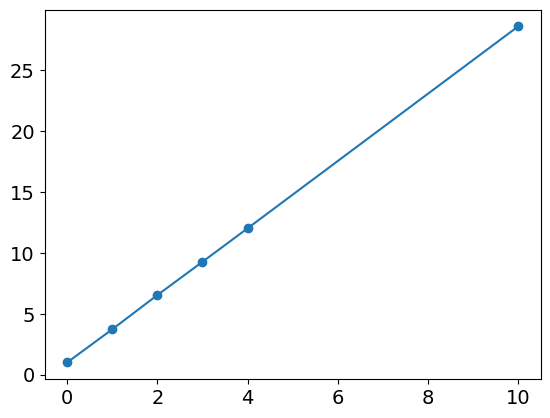

In [59]:
m = [0, 1, 2, 3, 4, 10]
plt.plot(m, fact, "-o")

In [154]:
def I_x(x, mode, waist, w, P_total, mux=0.0):
    n = mode[0]
    norm_n = 1.0 / jnp.sqrt((2.0**n) * jax.scipy.special.factorial(n))
    
    norm_factor = (2.0 / (jnp.pi * w**2))**0.25
    field_x = norm_factor * norm_n * jax_hermite(n, jnp.sqrt(2) * (x - mux) / w) * jnp.exp(-(x - mux)**2 / w**2)
    
    return jnp.sqrt(P_total) * (field_x**2)

def I_y(y, mode, waist, w, P_total, muy=0.0):
    m = mode[1]
    norm_m = 1.0 / jnp.sqrt((2.0 ** m) * jax.scipy.special.factorial(m))
    
    norm_factor = (2.0 / (jnp.pi * w ** 2)) ** 0.25
    field_y = norm_factor * norm_m * jax_hermite(m, jnp.sqrt(2) * (y - muy) / w) * jnp.exp(-(y - muy)**2 / w**2)
    
    return jnp.sqrt(P_total) * (field_y ** 2)

def dIy_dy_analytical(y, mode, waist, w, P_total, muy = 0.0):
    m = mode[1]
    norm_m = 1.0 / jnp.sqrt((2.0 ** m) * jax.scipy.special.factorial(m))
    norm_factor = (2.0 / (jnp.pi * w ** 2)) ** 0.25

    y_scaled = jnp.sqrt(2) * (y - muy) / w
    Hm = jax_hermite(m, y_scaled)
    dH_dy = jnp.where(
        m > 0,
        2.0 * m * jax_hermite(m - 1, y_scaled) * (jnp.sqrt(2) / w),
        0.0,
    )

    field_y = norm_factor * norm_m * Hm * jnp.exp(-((y - muy) ** 2) / w ** 2)
    dfield_dy = norm_factor * norm_m * dH_dy * jnp.exp(
        -((y - muy) ** 2) / w ** 2
    ) - field_y * (2.0 * (y - muy) / w ** 2)

    return 2.0 * P_total * field_y * dfield_dy

def x_integ(bounds, mode, waist, w, P_total, mux = 0.0):
    integ, info = quadgk(I_x, bounds, args=(mode, waist, w, P_total, mux))
    return integ

def y_integ(bounds, mode, waist, w, P_total, muy = 0.0):
    integ, info = quadgk(I_y, bounds, args=(mode, waist, w, P_total, muy))
    return integ
    
def diffmap(mu, r, gap, mode, waist, w, targ_power, mux):
    x_power = x_integ(jnp.array([-r, r]), mode, waist, w, targ_power, mux=mux)

    def diff(muy):
        if gap == 0:
            I_center = I_y(0.0, mode, waist, w, targ_power, muy=0.0)
            return x_power * (2.0 * I_center) * muy
        else:
            grad_at_edge = jnp.abs(
                dIy_dy_analytical(
                    gap / 2.0, mode, waist, w, targ_power, muy=0.0
                )
            )
            return x_power * (grad_at_edge * w) * muy

    return jax.vmap(diff)(mu)

def lsum(mu, r, gap, mode, waist, w, targ_power, mux):
    return x_integ(jnp.array([-r, r]), mode, waist, w, targ_power, mux = mux) * y_integ(jnp.array([gap / 2, r]), mode, waist, w, targ_power, muy = mu) + x_integ(jnp.array([-r, r]), mode, waist, w, targ_power, mux = mux) * y_integ(jnp.array([-r, -gap / 2]), mode, waist, w, targ_power, muy = mu)
    
old = []
new = []

for gap in np.linspace(0, r, 100):
    osc = 1e-9
    r = 3
    # gap = 5
    mode = [0, 0]
    waist = 1
    w = 1
    P = 1
    mux = 0
    P = P ** 2 / lsum(0, r, gap, mode, waist, w, P, mux)
    # print(lsum(0, r, gap, mode, waist, w, P, mux))
    old.append(diff(osc, r, gap, mode, waist, w, P, mux))
    
    import sympy as sp
    import scipy.special as special
    
    def DP(muy):
        n = mode[0]
        m = mode[1]
        x = sp.Symbol('x')
        y = sp.Symbol('y')
    
        bounds = np.array([gap / 2, r])
        if gap / 2 < r:
            Px = sp.sqrt(P) * sp.integrate((1.0 / sp.sqrt((2.0**n) * sp.factorial(n)) * (2.0 / (sp.pi * w**2))**0.25 * sp.hermite(n, np.sqrt(2) * (x - mux) / w) * sp.exp(-(x - mux)**2 / w ** 2)) ** 2, (x, -r, r))
            Py = sp.sqrt(P) * (sp.integrate((1.0 / sp.sqrt((2.0 ** m) * sp.factorial(m)) * (2.0 / (sp.pi * w ** 2)) ** 0.25 * sp.hermite(m, np.sqrt(2) * (y - muy) / w) * sp.exp(-(y - muy)**2 / w**2)) ** 2, (y, gap / 2, r)) - sp.integrate((1.0 / sp.sqrt((2.0 ** m) * sp.factorial(m)) * (2.0 / (sp.pi * w ** 2)) ** 0.25 * sp.hermite(m, np.sqrt(2) * (y - muy) / w) * sp.exp(-(y - muy)**2 / w**2)) ** 2, (y, -r, -gap / 2)))
            return Px * Py 
        else:
            return sp.Integer(0)
    
    new.append(DP(osc).evalf())

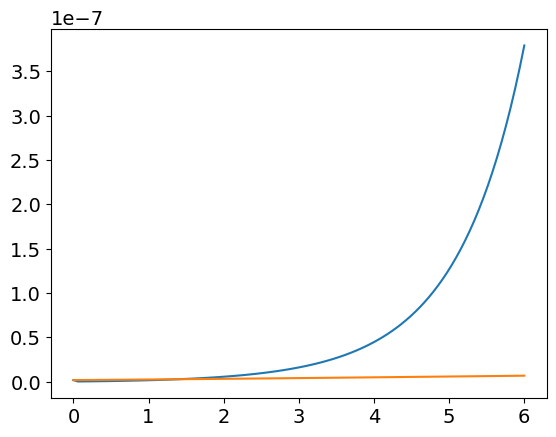

In [155]:
plt.plot(np.linspace(0, 2 * r, 100), old)
plt.plot(np.linspace(0, 2 * r, 100), new)
plt.show()